# 04. Train·Valid 이미지 변환 비교
`04_transforms.py`의 학습용 증강과 검증용 기본 변환을 같은 이미지에 적용해 시각적으로 비교합니다. 가로·세로 줄무늬 이미지 각각을 확인하고, 반복 적용 시 픽셀값 차이를 측정합니다.

## 0. 작업 전 준비사항
PyTorch, torchvision, Pillow, pandas, matplotlib이 설치된 커널에서 **Run All**로 실행합니다. CPU로 충분합니다. 그림과 CSV는 `20261102/02_응용/docs/outputs`에 저장합니다. 기존 Python 파일은 수정하지 않습니다.

### 실제 04번 파일을 기준으로 비교
현재 `04_transforms.py`의 train·valid 변환은 분리되어 있습니다. 학습용은 Resize → 무작위 좌우반전 → 무작위 회전 → 밝기 변화 → ToTensor이며, 검증용은 Resize → ToTensor입니다.

아래 코드는 실제 파일에서 두 변환 정의를 읽어 사용합니다. 원본과 같은 seed=42를 사용해 가로 줄무늬를 먼저 3회 증강하고, 추가로 세로 줄무늬도 비교합니다. 이번 노트북은 이미지 변환 비교이며 모델 학습이나 성능 평가는 수행하지 않습니다.


In [1]:
%matplotlib inline
from pathlib import Path
import torch
from torchvision import transforms
from PIL import Image
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

torch.set_num_threads(1)
cwd = Path.cwd().resolve()
day_root = next((candidate for parent in (cwd, *cwd.parents)
                 for candidate in (parent / "20261102", parent)
                 if (candidate / "02_응용" / "04_transforms.py").is_file()), None)
if day_root is None:
    raise FileNotFoundError("이 저장소 안에서 실행하세요.")
out = day_root / "02_응용" / "docs" / "outputs"
out.mkdir(parents=True, exist_ok=True)
images = {}
for label in ["horizontal", "vertical"]:
    path = sorted((day_root / "02_응용" / "data" / "train" / label).glob("*.png"))[0]
    with Image.open(path) as image:
        images[label] = image.convert("RGB")
    print(label, path.name, images[label].size)

horizontal train_horizontal_000.png (64, 64)
vertical train_vertical_000.png (64, 64)


## 1. 학습용과 검증용 변환을 구분하는 이유
| 변환 | Train | Valid | 역할 |
| --- | --- | --- | --- |
| Resize(64, 64) | 적용 | 적용 | 입력 공간 크기 통일 |
| RandomHorizontalFlip | 확률 0.5 | 생략 | 좌우 방향 변화 |
| RandomRotation(10) | -10~10도 무작위 회전 | 생략 | 작은 기울기 변화 |
| ColorJitter(brightness=0.15) | 밝기 계수 0.85~1.15 | 생략 | 밝기 변화 |
| ToTensor | 적용 | 적용 | RGB PNG를 CHW float32, 0~1 범위로 변환 |

Train은 같은 이미지에서도 여러 모습을 만들어 다양한 입력을 학습하게 합니다. Valid는 비교 조건을 일정하게 유지하기 위해 무작위 증강을 생략합니다. 고정 변환은 평가 입력의 무작위성을 줄이지만 전체 모델 실행의 결정성까지 보장하는 것은 아닙니다.

가로·세로 줄무늬에서 좌우반전은 라벨을 유지합니다. 90도 회전은 가로와 세로를 바꾸므로 사용하지 않습니다. 작은 회전은 라벨을 유지한다고 가정하지만, 회전 후 경계에는 기본 채움값 0으로 검은 부분이 생길 수 있습니다.

In [2]:
# 실제 파일에서 두 transform 정의만 읽어 실행합니다.
# 학습이나 파일 저장 등 원본의 나머지 코드는 실행하지 않습니다.
import ast
source_path = day_root / "02_응용" / "04_transforms.py"
module = ast.parse(source_path.read_text())
transform_nodes = [node for node in module.body
                   if isinstance(node, ast.Assign)
                   and any(isinstance(target, ast.Name)
                           and target.id in {"train_transform", "valid_transform"}
                           for target in node.targets)]
exec(compile(ast.Module(body=transform_nodes, type_ignores=[]), str(source_path), "exec"))
print("Train:", train_transform)
print("Valid:", valid_transform)

# seed는 반복문 바깥에서 한 번만 설정합니다.
# 매 호출 직전에 같은 seed로 초기화하면 같은 증강이 반복될 수 있습니다.
torch.manual_seed(42)
samples = {}
rows = []
for label, image in images.items():
    valid_views = [valid_transform(image) for _ in range(3)]
    train_views = [train_transform(image) for _ in range(3)]
    samples[label] = {"valid": valid_views, "train": train_views}
    for phase, views in samples[label].items():
        for i, tensor in enumerate(views):
            rows.append({"class": label, "phase": phase, "view": i + 1,
                         "shape": str(tuple(tensor.shape)),
                         "equal_to_first": torch.equal(views[0], tensor),
                         "mae_to_first": (views[0] - tensor).abs().mean().item(),
                         "mae_to_valid": (valid_views[0] - tensor).abs().mean().item()})
    assert all(torch.equal(valid_views[0], view) for view in valid_views)
    assert all(view.shape == (3, 64, 64) for view in valid_views + train_views)
results = pd.DataFrame(rows)
print(results.round(6).to_string(index=False))
results.to_csv(out / "transforms_comparison.csv", index=False)

Train: Compose(
    Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-10.0, 10.0], interpolation=nearest, expand=False, fill=0)
    ColorJitter(brightness=(0.85, 1.15), contrast=None, saturation=None, hue=None)
    ToTensor()
)
Valid: Compose(
    Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
)
     class phase  view       shape  equal_to_first  mae_to_first  mae_to_valid
horizontal valid     1 (3, 64, 64)            True      0.000000      0.000000
horizontal valid     2 (3, 64, 64)            True      0.000000      0.000000
horizontal valid     3 (3, 64, 64)            True      0.000000      0.000000
horizontal train     1 (3, 64, 64)            True      0.000000      0.106590
horizontal train     2 (3, 64, 64)           False      0.042732      0.080357
horizontal train     3 (3, 64, 64)           False      0.099881      0.018769
  vertical valid 

## 2. 같은 이미지에 반복 적용한 결과
윗줄은 동일한 이미지에 valid 변환을 세 번 적용한 결과, 아랫줄은 train 변환을 세 번 적용한 결과입니다. 텐서는 CHW에서 HWC로 바꿔 표시합니다. 이미지별 차이를 비교하려고 train 폴더의 **동일한 원본**을 양쪽 변환에 넣었습니다. 실제 valid 데이터로 성능을 평가하는 실험은 아닙니다.

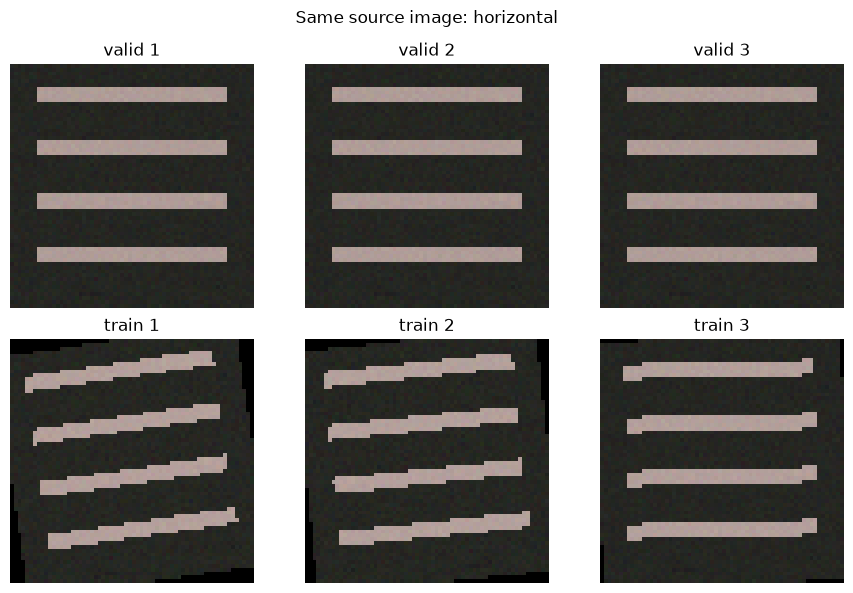

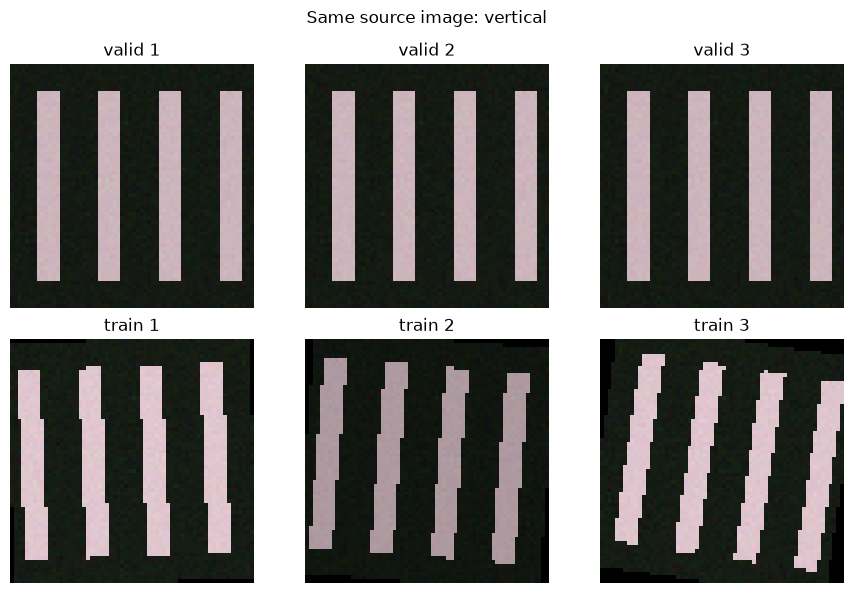

In [3]:
for label, views in samples.items():
    fig, axes = plt.subplots(2, 3, figsize=(9, 6))
    for row, phase in enumerate(["valid", "train"]):
        for col, tensor in enumerate(views[phase]):
            axes[row, col].imshow(tensor.permute(1, 2, 0).numpy())
            axes[row, col].set_title(f"{phase} {col + 1}")
            axes[row, col].set_axis_off()
    fig.suptitle(f"Same source image: {label}")
    fig.tight_layout()
    fig.savefig(out / f"transforms_{label}_views.png", dpi=140)
    plt.show()
    plt.close(fig)

### Valid 기준 픽셀 차이 시각화
아래 값은 `abs(train - valid)`를 RGB 채널별로 계산한 뒤 평균한 것입니다. 두 클래스와 세 증강에 동일한 색 범위를 사용합니다. 위치 변화와 밝기 변화가 함께 반영되며, 차이가 크다는 것만으로 증강이 더 좋다고 판단하지 않습니다. 회전은 위치를 바꾸므로 픽셀별 차이는 증강 효과의 품질 지표가 아닙니다.

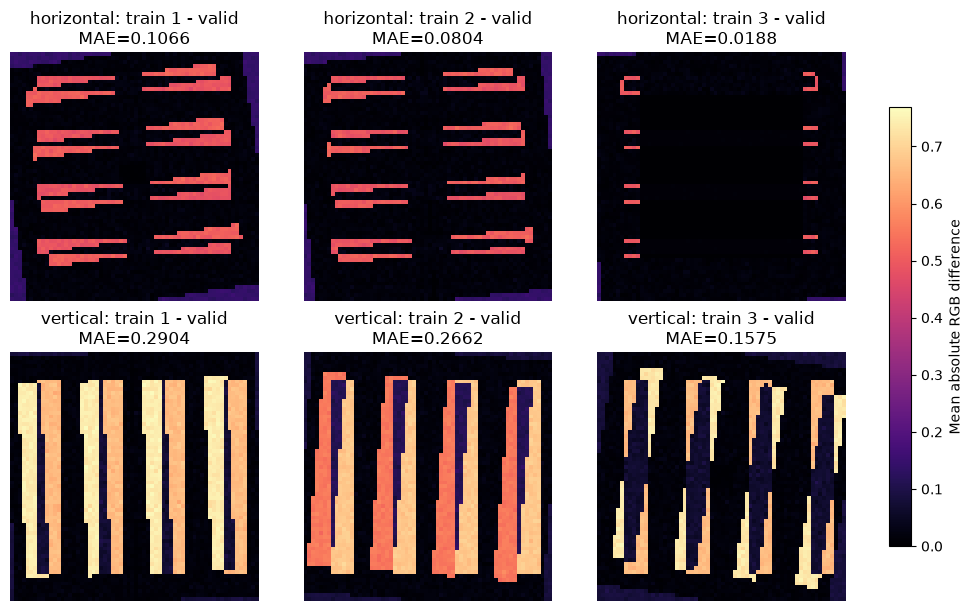

In [4]:
differences = {label: [(view - views["valid"][0]).abs().mean(dim=0)
                       for view in views["train"]]
               for label, views in samples.items()}
vmax = max(diff.max().item() for values in differences.values() for diff in values)
fig, axes = plt.subplots(2, 3, figsize=(10, 6), constrained_layout=True)
for row, (label, values) in enumerate(differences.items()):
    for col, diff in enumerate(values):
        im = axes[row, col].imshow(diff.numpy(), cmap="magma", vmin=0, vmax=vmax)
        axes[row, col].set_title(f"{label}: train {col+1} - valid\nMAE={diff.mean().item():.4f}")
        axes[row, col].set_axis_off()
fig.colorbar(im, ax=axes, label="Mean absolute RGB difference", shrink=0.8)
fig.savefig(out / "transforms_pixel_differences.png", dpi=140)
plt.show()
plt.close(fig)

## 3. 반복 적용 시 같은 결과가 나오는지 확인
실제 파일처럼 같은 이미지에 train 변환과 valid 변환을 반복 적용합니다. 여기서는 각 5회 실행하여 첫 출력과 같은지, 첫 출력 대비 평균 절대 차이(MAE)가 얼마인지 측정합니다.

Valid는 무작위 연산이 없어 같은 결과를 만듭니다. Train은 무작위 연산이 있지만 우연히 같은 결과가 나올 수도 있습니다. 특히 대칭적인 줄무늬는 좌우반전만으로 차이가 작을 수 있습니다. Train 출력이 매번 달라야 한다는 assert는 사용하지 않습니다.


In [5]:
torch.manual_seed(42)
image = images["horizontal"]
checks = []
for name, transform in [("train", train_transform),
                         ("valid", valid_transform)]:
    views = [transform(image) for _ in range(5)]
    checks.append({"pipeline": name,
                   "all_5_equal": all(torch.equal(views[0], view) for view in views),
                   "mean_mae_to_first": sum((views[0] - view).abs().mean().item()
                                            for view in views[1:]) / 4})
checks = pd.DataFrame(checks)
print(checks.to_string(index=False))
checks.to_csv(out / "transforms_valid_repeatability.csv", index=False)
assert checks.loc[checks["pipeline"] == "valid", "all_5_equal"].item()

pipeline  all_5_equal  mean_mae_to_first
   train        False           0.094264
   valid         True           0.000000


## 4. 결과 해석 및 추가 실험
두 파이프라인 모두 출력 shape는 `(3, 64, 64)`입니다. Shape가 같아도 train은 무작위 회전·밝기 변화 등으로 픽셀값이 달라질 수 있고, valid는 같은 원본에서 같은 결과를 만듭니다. 위 실행 결과의 표에 실제 동일 여부와 MAE를 기록했습니다.

| 비교 항목 | Train | Valid |
| --- | --- | --- |
| 공간 크기·채널 | 64×64, RGB 3채널 | 64×64, RGB 3채널 |
| 같은 이미지 반복 적용 | 무작위 증강으로 달라질 수 있음 | 같은 픽셀값 유지 |
| 목적 | 다양한 입력을 학습할 수 있도록 변형 | 일정한 평가 입력 유지 |
| 이번 데이터의 라벨 | 작은 회전·밝기·좌우반전으로 보존한다고 가정 | 그대로 유지 |

그림의 회전된 줄무늬, 경계의 검은 채움, 밝기 차이를 확인합니다. 이번 입력은 이미 64×64이므로 Resize가 공간 크기를 바꾸지는 않습니다. 두 클래스 모두 train 폴더에서 같은 원본을 선택해 양쪽 변환에 넣었으므로, 그림의 차이는 train·valid의 서로 다른 파일에서 생긴 차이가 아닙니다.

픽셀 MAE는 위치와 밝기의 변화를 합쳐 보여 주는 수치입니다. 더 큰 차이가 더 좋은 증강이나 더 높은 정확도를 뜻하지 않습니다. 성능에 대한 결론은 별도 학습·검증 실험이 필요합니다.

### 직접 확인해 볼 내용
- Train에서 회전 또는 밝기 변화를 하나씩 제거하고 시각적 변화와 MAE를 비교합니다.
- 좌우반전만 남기면 줄무늬의 대칭성 때문에 결과가 같거나 비슷할 수 있는지 확인합니다.
- 90도 회전은 가로·세로 라벨을 바꾸므로 이 실습의 라벨 보존 증강으로 사용하지 않습니다.
- 같은 seed로 노트북 전체를 다시 실행해 현재 환경에서 재현되는지 확인합니다. 호출마다 seed를 초기화하면 증강이 반복될 수 있습니다. 라이브러리 버전이 달라지면 결과가 달라질 수 있습니다.

### 자주 하는 실수 점검
- Valid에 무작위 train 변환을 연결하지 않았는가?
- CHW 텐서를 표시할 때 HWC로 변환했는가?
- Shape가 같다는 이유로 픽셀값도 같다고 판단하지 않았는가?
- `model.eval()`은 Dataset transform을 바꾸지 않으므로, 검증용 변환을 별도로 설정했는가?
